In [5]:
# 1. Entorno, semillas y librerías
import sys, os, random, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import ast

import wfdb
from scipy import signal as sp_signal
from scipy.signal import sosfiltfilt, iirnotch, tf2sos
from sklearn.metrics import classification_report, multilabel_confusion_matrix, roc_auc_score, precision_recall_curve

import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

print(sys.executable)
print("TensorFlow:", tf.__version__)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

C:\Users\Usuario\anaconda3\envs\tfg\python.exe
TensorFlow: 2.16.1


In [6]:
# 2. Configuración general
DATA_DIR  = Path(r"C:\Users\Usuario\Desktop\TFG\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3")
CACHE_DIR = DATA_DIR / "cache_v2" / "con_filtrado"

MODEL_DIR = Path("./outputs/models")
FIG_DIR   = Path("./outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

FS = 100
SUPER_CLASSES = ["NORM", "MI", "STTC", "HYP", "CD"]
CLASS_MAP_HUMAN = {
    "NORM": "Normal", "MI": "Infarto", "STTC": "Isquemia/ST-T",
    "HYP": "Hipertrofia", "CD": "Conducción (bloqueos)",
}

BANDPASS_LOW  = 0.5
BANDPASS_HIGH = 40.0
NOTCH_FREQ    = 50.0
NOTCH_Q       = 30.0

STFT_NPERSEG  = 64
STFT_NOVERLAP = 48
SPEC_SHAPE    = (33, 64)

In [7]:
# 3. Carga de metadatos y etiquetas multi-etiqueta
df  = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
scp = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)
df.columns  = df.columns.str.strip()
scp.columns = scp.columns.str.strip()

scp_super = (scp[scp["diagnostic_class"].notna()][["diagnostic_class"]]
             .rename(columns={"diagnostic_class": "superclass"}))

def extract_superclasses(scp_codes_str):
    """Convierte el string tipo diccionario de scp_codes en la lista de superclases presentes."""
    if pd.isna(scp_codes_str):
        return []
    try:
        d = ast.literal_eval(scp_codes_str)
        if not isinstance(d, dict):
            return []
    except Exception:
        return []
    return list({scp_super.loc[k, "superclass"] for k in d.keys() if k in scp_super.index})

def multilabel_vector(classes):
    """Convierte la lista de superclases en un vector binario de tamaño 5."""
    s = set(classes)
    return np.array([1 if c in s else 0 for c in SUPER_CLASSES], dtype=np.int32)

df["superclasses"] = df["scp_codes"].apply(extract_superclasses)
df = df[df["superclasses"].apply(len) > 0].reset_index()
df["target_vec"] = df["superclasses"].apply(multilabel_vector)

In [8]:
# 4. Split por paciente
test_df = df[df["strat_fold"] == 10].reset_index(drop=True)
print("Tamaño de test:", len(test_df))

Tamaño de test: 2158


In [9]:
# 5. Preprocesado y espectrograma STFT (idéntico a 02-05 y 09)
def is_valid_signal(x, flat_std_thresh=1e-6):
    """Descarta derivaciones corruptas: con NaN/Inf o completamente planas (fallo de electrodo)."""
    if np.any(np.isnan(x)) or np.any(np.isinf(x)):
        return False
    return np.std(x) >= flat_std_thresh

_BP_SOS    = sp_signal.butter(4, [BANDPASS_LOW / (FS/2), BANDPASS_HIGH / (FS/2)], btype="band", output="sos")
_NOTCH_SOS = tf2sos(*iirnotch(NOTCH_FREQ / (FS/2), NOTCH_Q))

def clean_lead(x):
    """Limpia una derivación (1D): paso-banda + notch + normalización z-score."""
    x = np.asarray(x, dtype=np.float64)
    if not is_valid_signal(x):
        return None
    x = sosfiltfilt(_BP_SOS, x)
    x = sosfiltfilt(_NOTCH_SOS, x)
    mu, sigma = x.mean(), x.std()
    if sigma < 1e-8:
        return None
    return ((x - mu) / sigma).astype(np.float32)

def preprocess_ecg(raw_signal):
    """Limpia las 12 derivaciones de un ECG. Descarta el registro si más de la mitad fallan."""
    cleaned = np.zeros_like(raw_signal, dtype=np.float32)
    n_bad = 0
    for i in range(raw_signal.shape[1]):
        c = clean_lead(raw_signal[:, i])
        cleaned[:, i] = c if c is not None else 0.0
        n_bad += (c is None)
    return None if n_bad > raw_signal.shape[1] // 2 else cleaned

def lead_to_spectrogram(lead_signal, fs=FS, nperseg=STFT_NPERSEG, noverlap=STFT_NOVERLAP, out_shape=SPEC_SHAPE):
    """Convierte una derivación 1D en su espectrograma STFT normalizado, con forma fija (F, T)."""
    _, _, Zxx = sp_signal.stft(lead_signal, fs=fs, nperseg=nperseg, noverlap=noverlap)
    mag = np.log1p(np.abs(Zxx))

    F, T = out_shape
    mag = mag[:F, :T]
    if mag.shape != (F, T):
        pad = np.zeros((F, T), dtype=np.float32)
        pad[:mag.shape[0], :mag.shape[1]] = mag
        mag = pad

    mn, mx = mag.min(), mag.max()
    if mx - mn > 1e-8:
        mag = (mag - mn) / (mx - mn)
    return mag.astype(np.float32)

def ecg_to_tensor(signal_2d):
    """signal_2d: (n_muestras, 12) -> tensor (F, T, 12)."""
    specs = [lead_to_spectrogram(signal_2d[:, i]) for i in range(signal_2d.shape[1])]
    return np.stack(specs, axis=-1)

In [10]:
# 6. Carga de X_test, Y_test desde el caché existente
def _cache_path(rel_path):
    h = hashlib.md5(rel_path.encode()).hexdigest()
    return CACHE_DIR / f"{h}.npy"

def get_tensor_cached(rel_path):
    cp = _cache_path(rel_path)
    if cp.exists():
        return np.load(cp)
    raw, _ = wfdb.rdsamp(str(DATA_DIR / rel_path))
    clean = preprocess_ecg(raw)
    if clean is None:
        return None
    tensor = ecg_to_tensor(clean)
    np.save(cp, tensor)
    return tensor

def build_split(df_split):
    Xs, Ys = [], []
    for _, row in df_split.iterrows():
        t = get_tensor_cached(row["filename_lr"])
        if t is None:
            continue
        Xs.append(t)
        Ys.append(row["target_vec"])
    return np.stack(Xs).astype(np.float32), np.stack(Ys).astype(np.float32)

X_test, Y_test = build_split(test_df)
print("Forma de test:", X_test.shape)

Forma de test: (2158, 33, 64, 12)


In [11]:
# 7. Carga del modelo final y recálculo de umbrales óptimos sobre validación
model = tf.keras.models.load_model(MODEL_DIR / "05_cnn_profunda_balanceo_umbral.keras", compile=False)

val_df = df[df["strat_fold"] == 9].reset_index(drop=True)
X_val, Y_val = build_split(val_df)

val_probs = model.predict(X_val, verbose=0)

best_thresholds = {}
for i, c in enumerate(SUPER_CLASSES):
    prec, rec, thr = precision_recall_curve(Y_val[:, i], val_probs[:, i])
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-8, None)
    best_i = np.nanargmax(f1[:-1]) if len(thr) > 0 else 0
    best_thresholds[c] = float(thr[best_i]) if len(thr) > 0 else 0.5

THRESH_VEC = np.array([best_thresholds[c] for c in SUPER_CLASSES])
print("Umbrales recalculados sobre validación:", best_thresholds)

Umbrales recalculados sobre validación: {'NORM': 0.4524393677711487, 'MI': 0.42697495222091675, 'STTC': 0.6164358854293823, 'HYP': 0.6522840261459351, 'CD': 0.7015767097473145}


In [13]:
# 8. Predicción sobre test y binarización con umbral óptimo por clase
test_probs = model.predict(X_test, verbose=0)
test_pred  = (test_probs >= THRESH_VEC).astype(int)

In [14]:
# 9. Informe de clasificación (macro, weighted, samples)
report = classification_report(
    Y_test, test_pred,
    target_names=[CLASS_MAP_HUMAN[c] for c in SUPER_CLASSES],
    zero_division=0,
)
print(report)

                       precision    recall  f1-score   support

               Normal       0.76      0.92      0.83       963
              Infarto       0.55      0.77      0.65       550
        Isquemia/ST-T       0.66      0.81      0.73       521
          Hipertrofia       0.47      0.49      0.48       262
Conducción (bloqueos)       0.75      0.61      0.68       496

            micro avg       0.66      0.78      0.72      2792
            macro avg       0.64      0.72      0.67      2792
         weighted avg       0.67      0.78      0.71      2792
          samples avg       0.70      0.79      0.72      2792



In [15]:
# 10. AUC por clase
auc_por_clase = {}
for i, c in enumerate(SUPER_CLASSES):
    if len(np.unique(Y_test[:, i])) < 2:
        auc_por_clase[c] = np.nan
    else:
        auc_por_clase[c] = roc_auc_score(Y_test[:, i], test_probs[:, i])

auc_macro = np.nanmean(list(auc_por_clase.values()))
print("AUC por clase:", {CLASS_MAP_HUMAN[c]: round(v, 4) for c, v in auc_por_clase.items()})
print("AUC macro:", round(auc_macro, 4))

AUC por clase: {'Normal': 0.9211, 'Infarto': 0.857, 'Isquemia/ST-T': 0.9183, 'Hipertrofia': 0.8204, 'Conducción (bloqueos)': 0.8767}
AUC macro: 0.8787


NameError: name 'cms' is not defined

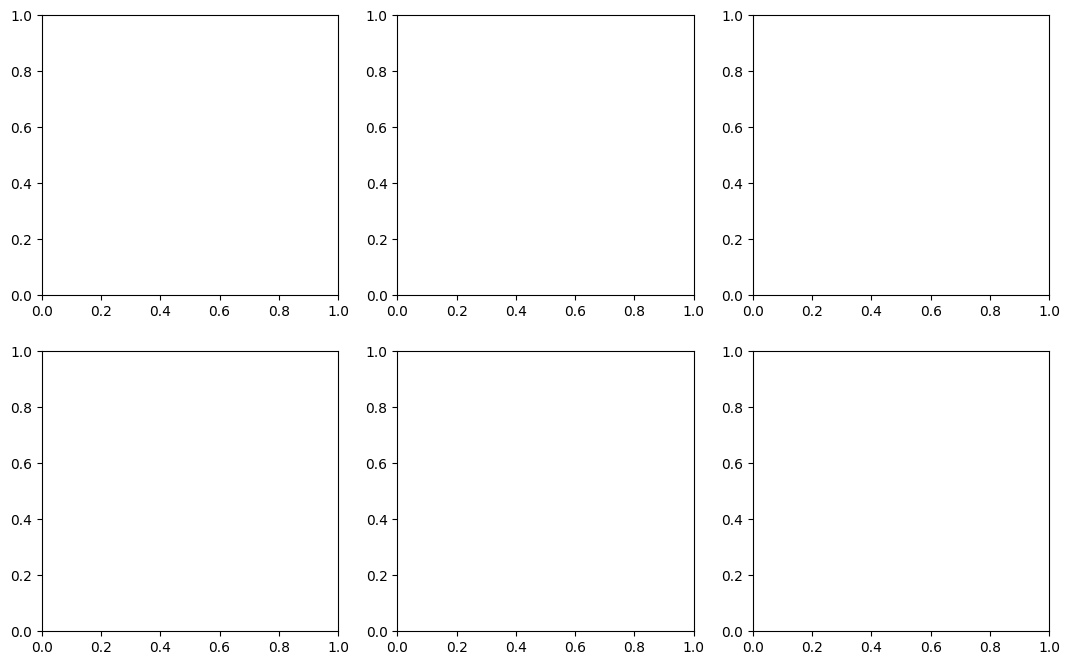

In [16]:
# 11. Matriz de confusión combinada, normalizada por fila
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

for i, c in enumerate(SUPER_CLASSES):
    cm = cms[i]
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    sns.heatmap(
        cm_norm, annot=True, fmt=".1%", cmap="Blues", cbar=False,
        xticklabels=["Pred. Neg", "Pred. Pos"],
        yticklabels=["Real Neg", "Real Pos"],
        vmin=0, vmax=1, ax=axes[i],
        annot_kws={"size": 11},
    )
    axes[i].set_title(f"{CLASS_MAP_HUMAN[c]} (umbral = {THRESH_VEC[i]:.3f})", fontsize=11)

axes[5].axis("off")  # sexto hueco vacío, al haber solo 5 clases

plt.tight_layout()
plt.savefig(FIG_DIR / "matrices_confusion_combinadas.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
# 12. Función de diagnóstico automático sobre un ECG nuevo
def diagnosticar_ecg(rel_path):
    """Carga un ECG crudo desde disco, aplica todo el proceso (preprocesado + STFT +
    predicción) y devuelve el diagnóstico según los umbrales óptimos por clase."""
    raw, _ = wfdb.rdsamp(str(DATA_DIR / rel_path))
    clean = preprocess_ecg(raw)
    if clean is None:
        return None
    tensor = ecg_to_tensor(clean)
    prob = model.predict(tensor[np.newaxis, ...], verbose=0)[0]
    pred = (prob >= THRESH_VEC).astype(int)

    resultado = {
        CLASS_MAP_HUMAN[c]: {"probabilidad": float(prob[i]), "umbral": float(THRESH_VEC[i]),
                              "positivo": bool(pred[i])}
        for i, c in enumerate(SUPER_CLASSES)
    }
    return resultado

In [26]:
def acierta_patologia(row):
    diag = diagnosticar_ecg(row["filename_lr"])
    if diag is None:
        return False
    reales = {CLASS_MAP_HUMAN[c] for c in row["superclasses"]}
    predichas = {clase for clase, info in diag.items() if info["positivo"]}
    return predichas == reales

    candidatos_acierto = candidatos.sample(n=min(50, len(candidatos)), random_state=SEED)

ejemplo_acierto = None
for _, row in candidatos_acierto.iterrows():
    if acierta_patologia(row):
        ejemplo_acierto = row
        break

if ejemplo_acierto is not None:
    diagnostico = diagnosticar_ecg(ejemplo_acierto["filename_lr"])
    print("ECG:", ejemplo_acierto["ecg_id"], "-", ejemplo_acierto["filename_lr"])
    print("Etiqueta real:", ejemplo_acierto["superclasses"])
    print()
    for clase, info in diagnostico.items():
        marca = "POSITIVO" if info["positivo"] else "negativo"
        print(f"{clase:22s} prob={info['probabilidad']:.3f}  umbral={info['umbral']:.3f}  -> {marca}")
else:
    print("No se encontró acierto completo en los primeros 50 candidatos probados.")

ECG: 18937 - records100/18000/18937_lr
Etiqueta real: ['STTC']

Normal                 prob=0.273  umbral=0.452  -> negativo
Infarto                prob=0.260  umbral=0.427  -> negativo
Isquemia/ST-T          prob=0.835  umbral=0.616  -> POSITIVO
Hipertrofia            prob=0.320  umbral=0.652  -> negativo
Conducción (bloqueos)  prob=0.144  umbral=0.702  -> negativo


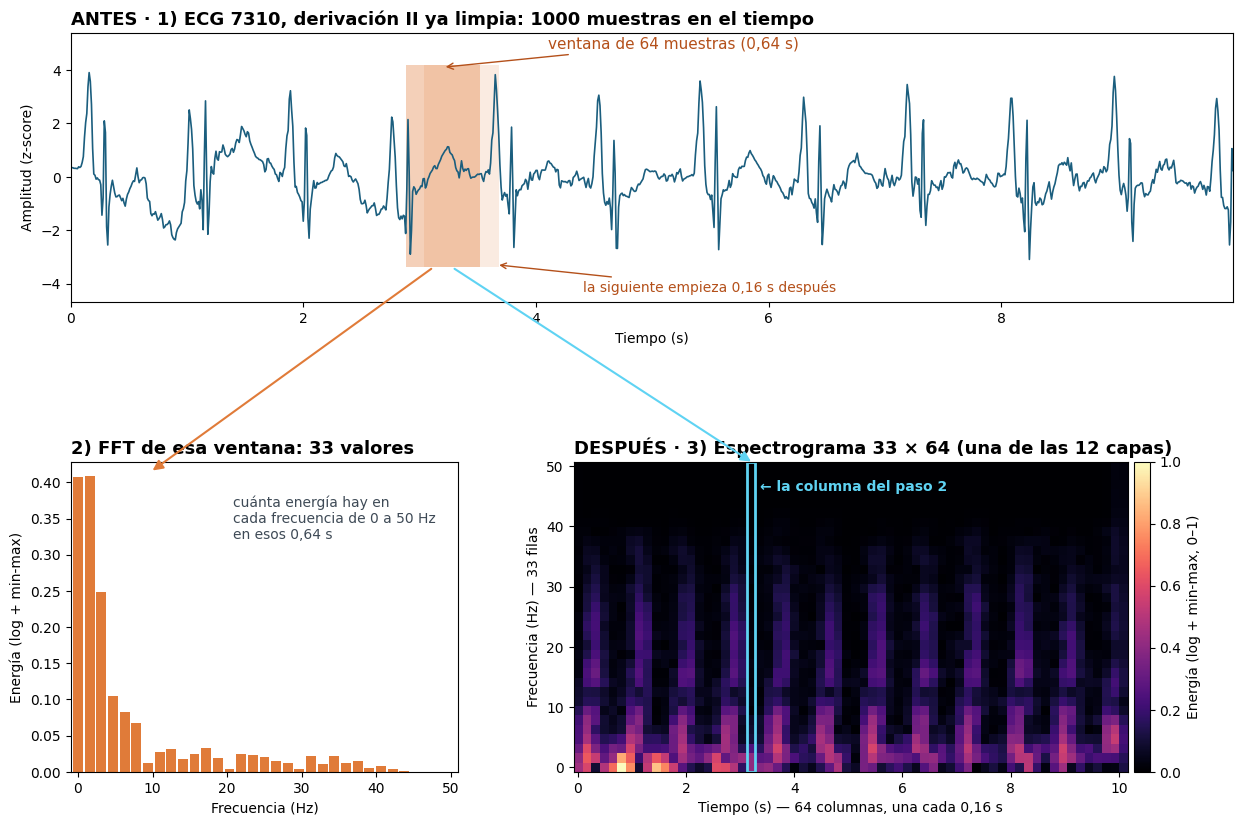

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import wfdb
from scipy import signal as sp_signal
from scipy.signal import sosfiltfilt, iirnotch, tf2sos

DATA_DIR = Path(r"C:\Users\Usuario\Desktop\TFG\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3")

FS = 100
BANDPASS_LOW = 0.5
BANDPASS_HIGH = 40.0
NOTCH_FREQ = 50.0
NOTCH_Q = 30.0
STFT_NPERSEG = 64
STFT_NOVERLAP = 48
SPEC_SHAPE = (33, 64)

df = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")

def is_valid_signal(x, flat_std_thresh=1e-6):
    if np.any(np.isnan(x)) or np.any(np.isinf(x)):
        return False
    return np.std(x) >= flat_std_thresh

_BP_SOS = sp_signal.butter(4, [BANDPASS_LOW / (FS / 2), BANDPASS_HIGH / (FS / 2)], btype="band", output="sos")
_NOTCH_SOS = tf2sos(*iirnotch(NOTCH_FREQ / (FS / 2), NOTCH_Q))

def clean_lead(x):
    x = np.asarray(x, dtype=np.float64)
    if not is_valid_signal(x):
        return None
    x = sosfiltfilt(_BP_SOS, x)
    x = sosfiltfilt(_NOTCH_SOS, x)
    mu, sigma = x.mean(), x.std()
    if sigma < 1e-8:
        return None
    return ((x - mu) / sigma).astype(np.float32)

def preprocess_ecg(raw_signal):
    cleaned = np.zeros_like(raw_signal, dtype=np.float32)
    n_bad = 0
    for i in range(raw_signal.shape[1]):
        c = clean_lead(raw_signal[:, i])
        cleaned[:, i] = c if c is not None else 0.0
        n_bad += (c is None)
    return None if n_bad > raw_signal.shape[1] // 2 else cleaned

def lead_to_spectrogram(lead_signal, fs=FS, nperseg=STFT_NPERSEG, noverlap=STFT_NOVERLAP, out_shape=SPEC_SHAPE):
    _, _, Zxx = sp_signal.stft(lead_signal, fs=fs, nperseg=nperseg, noverlap=noverlap)
    mag = np.log1p(np.abs(Zxx))
    F, T = out_shape
    mag = mag[:F, :T]
    if mag.shape != (F, T):
        pad = np.zeros((F, T), dtype=np.float32)
        pad[:mag.shape[0], :mag.shape[1]] = mag
        mag = pad
    mn, mx = mag.min(), mag.max()
    if mx - mn > 1e-8:
        mag = (mag - mn) / (mx - mn)
    return mag.astype(np.float32)

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, ConnectionPatch

ECG_ID = 7310
DERIVACION = 1
NOMBRES = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
COLUMNA = 20

ruta = df.loc[ECG_ID, "filename_lr"]
raw, _ = wfdb.rdsamp(str(DATA_DIR / ruta))
limpia = preprocess_ecg(raw)
x = limpia[:, DERIVACION]
espec = lead_to_spectrogram(x)

paso = STFT_NPERSEG - STFT_NOVERLAP
t = np.arange(len(x)) / FS
t_col = np.arange(espec.shape[1]) * paso / FS
f = np.arange(espec.shape[0]) * FS / STFT_NPERSEG
c = t_col[COLUMNA]
mitad = STFT_NPERSEG / (2 * FS)
dt = paso / FS
df_hz = FS / STFT_NPERSEG
columna = espec[:, COLUMNA]

fig = plt.figure(figsize=(15, 9.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.7], height_ratios=[1, 1.15], hspace=0.55, wspace=0.22)
ax_t = fig.add_subplot(gs[0, :])
ax_f = fig.add_subplot(gs[1, 0])
ax_s = fig.add_subplot(gs[1, 1])

ax_t.plot(t, x, color="#1B5E7E", lw=1.2)
y0, y1 = x.min(), x.max()
for centro, alfa in [(c, 0.35), (t_col[COLUMNA + 1], 0.15)]:
    ax_t.add_patch(Rectangle((centro - mitad, y0 - 0.3), 2 * mitad, y1 - y0 + 0.6, color="#E07B39", alpha=alfa, lw=0))
ax_t.annotate(f"ventana de {STFT_NPERSEG} muestras ({STFT_NPERSEG / FS:.2f} s)".replace(".", ","),
              xy=(c, y1 + 0.2), xytext=(c + 0.9, y1 + 0.9), fontsize=11, color="#B4501A",
              arrowprops=dict(arrowstyle="->", color="#B4501A"))
ax_t.annotate(f"la siguiente empieza {dt:.2f} s después".replace(".", ","),
              xy=(t_col[COLUMNA + 1] + mitad - 0.02, y0 - 0.2), xytext=(c + 1.2, y0 - 1.2), fontsize=10,
              color="#B4501A", arrowprops=dict(arrowstyle="->", color="#B4501A"))
ax_t.set_xlim(0, t[-1])
ax_t.set_ylim(y0 - 1.6, y1 + 1.5)
ax_t.set_xlabel("Tiempo (s)")
ax_t.set_ylabel("Amplitud (z-score)")
ax_t.set_title(f"ANTES · 1) ECG {ECG_ID}, derivación {NOMBRES[DERIVACION]} ya limpia: {len(x)} muestras en el tiempo",
               loc="left", fontsize=13, fontweight="bold")

ax_f.bar(f, columna, width=df_hz * 0.85, color="#E07B39")
ax_f.set_xlabel("Frecuencia (Hz)")
ax_f.set_ylabel("Energía (log + min-max)")
ax_f.set_xlim(-1, FS / 2 + 1)
ax_f.set_title(f"2) FFT de esa ventana: {espec.shape[0]} valores", loc="left", fontsize=13, fontweight="bold")
ax_f.text(0.42, 0.75, f"cuánta energía hay en\ncada frecuencia de 0 a {FS // 2} Hz\nen esos {STFT_NPERSEG / FS:.2f} s".replace(".", ","),
          transform=ax_f.transAxes, fontsize=10, color="#3E4A56")

im = ax_s.imshow(espec, origin="lower", aspect="auto", cmap="magma",
                 extent=[t_col[0] - dt / 2, t_col[-1] + dt / 2, -df_hz / 2, f[-1] + df_hz / 2])
ax_s.add_patch(Rectangle((c - dt / 2, -df_hz / 2), dt, f[-1] + df_hz, fill=False, ec="#5FD3F3", lw=2))
ax_s.text(c + dt, f[-1] * 0.92, "← la columna del paso 2", color="#5FD3F3", fontsize=10, fontweight="bold")
ax_s.set_xlabel(f"Tiempo (s) — {espec.shape[1]} columnas, una cada {dt:.2f} s".replace(".", ","))
ax_s.set_ylabel(f"Frecuencia (Hz) — {espec.shape[0]} filas")
ax_s.set_title(f"DESPUÉS · 3) Espectrograma {espec.shape[0]} × {espec.shape[1]} (una de las 12 capas)",
               loc="left", fontsize=13, fontweight="bold")
barra = fig.colorbar(im, ax=ax_s, pad=0.01)
barra.set_label("Energía (log + min-max, 0–1)")

fig.add_artist(ConnectionPatch((c - 0.1, y0 - 0.35), (10, columna.max() * 1.02), "data", "data",
                               axesA=ax_t, axesB=ax_f, arrowstyle="-|>", color="#E07B39", lw=1.5, mutation_scale=15))
fig.add_artist(ConnectionPatch((c + 0.1, y0 - 0.35), (c, f[-1] + df_hz / 2), "data", "data",
                               axesA=ax_t, axesB=ax_s, arrowstyle="-|>", color="#5FD3F3", lw=1.5, mutation_scale=15))

plt.savefig("figura_stft_antes_despues.png", dpi=300, bbox_inches="tight")
plt.show()

ECG de prueba con una sola superclase: 1650 de 2158
Aciertos totales: 1207 de 1650 (73.2%)
Normal                   n =  912   acierto 91.1%   principal confusión: Isquemia/ST-T (4.3%)
Infarto                  n =  256   acierto 49.6%   principal confusión: Normal (35.5%)
Isquemia/ST-T            n =  242   acierto 64.0%   principal confusión: Normal (17.8%)
Hipertrofia              n =   56   acierto 0.0%   principal confusión: Normal (67.9%)
Conducción (bloqueos)    n =  184   acierto 51.1%   principal confusión: Normal (27.7%)

Matriz de recuentos (filas = real, columnas = predicha):
[[831  24  39   2  16]
 [ 91 127  26   0  12]
 [ 43  37 155   2   5]
 [ 38   8   9   0   1]
 [ 51  32   7   0  94]]


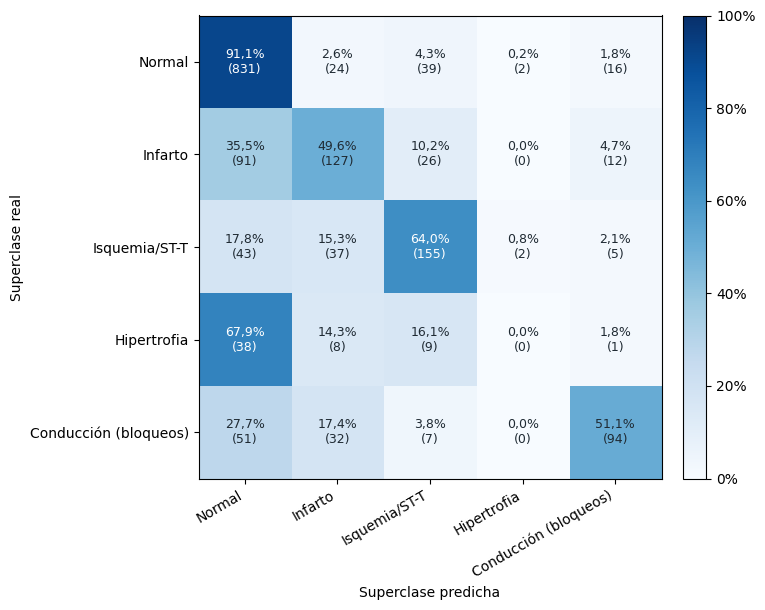

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

if "test_probs" not in globals():
    test_probs = model.predict(X_test, verbose=0)
    
nombres = [CLASS_MAP_HUMAN[c] for c in SUPER_CLASSES]
n = len(SUPER_CLASSES)

una_clase = Y_test.sum(axis=1) == 1
y_real = Y_test[una_clase].argmax(axis=1)
y_pred = (test_probs[una_clase] / np.asarray(THRESH_VEC)).argmax(axis=1)

cm = np.zeros((n, n), dtype=int)
for r, p in zip(y_real, y_pred):
    cm[r, p] += 1
cm_pct = cm / cm.sum(axis=1, keepdims=True)

print(f"ECG de prueba con una sola superclase: {una_clase.sum()} de {len(Y_test)}")
print(f"Aciertos totales: {np.trace(cm)} de {cm.sum()} ({np.trace(cm) / cm.sum():.1%})")
for i in range(n):
    fila = cm_pct[i].copy()
    fila[i] = -1
    j = fila.argmax()
    print(f"{nombres[i]:<24} n = {cm[i].sum():4d}   acierto {cm_pct[i, i]:.1%}   principal confusión: {nombres[j]} ({cm_pct[i, j]:.1%})")
print("\nMatriz de recuentos (filas = real, columnas = predicha):")
print(cm)

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
for i in range(n):
    for j in range(n):
        texto = f"{cm_pct[i, j]:.1%}".replace(".", ",") + f"\n({cm[i, j]})"
        ax.text(j, i, texto, ha="center", va="center", fontsize=9,
                color="white" if cm_pct[i, j] > 0.55 else "#1f2a33")
ax.set_xticks(range(n))
ax.set_xticklabels(nombres, rotation=30, ha="right")
ax.set_yticks(range(n))
ax.set_yticklabels(nombres)
ax.set_xlabel("Superclase predicha")
ax.set_ylabel("Superclase real")
barra = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
barra.ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
plt.tight_layout()
Path("outputs/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("outputs/figures/matriz_confusion_5x5.png", dpi=220, bbox_inches="tight")
plt.show()


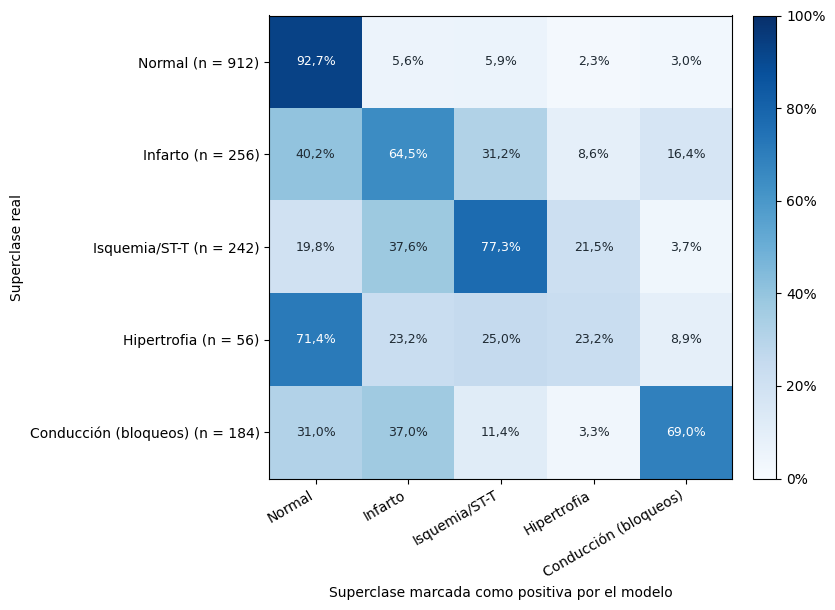

In [20]:
pred_bin = (test_probs >= np.asarray(THRESH_VEC)).astype(int)
una_clase = Y_test.sum(axis=1) == 1
y_real = Y_test[una_clase].argmax(axis=1)
P = pred_bin[una_clase]

tabla = np.zeros((n, n))
for i in range(n):
    tabla[i] = P[y_real == i].mean(axis=0)

fig, ax = plt.subplots(figsize=(7.8, 6.2))
im = ax.imshow(tabla, cmap="Blues", vmin=0, vmax=1)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{tabla[i, j]:.1%}".replace(".", ","), ha="center", va="center", fontsize=9,
                color="white" if tabla[i, j] > 0.55 else "#1f2a33")
ax.set_xticks(range(n))
ax.set_xticklabels(nombres, rotation=30, ha="right")
ax.set_yticks(range(n))
ax.set_yticklabels([f"{nombres[i]} (n = {(y_real == i).sum()})" for i in range(n)])
ax.set_xlabel("Superclase marcada como positiva por el modelo")
ax.set_ylabel("Superclase real")
barra = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
barra.ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
plt.tight_layout()
plt.savefig("outputs/figures/matriz_confusion_5x5.png", dpi=220, bbox_inches="tight")
plt.show()
